# 03_models_and_tuning.ipynb — Baseline & Framework Models, Architecture & Tuning

**Module:** NB6057CEM Artificial Neural Networks — CW1 Practical  
**Task:** Task T3 — Baseline & Framework Models & Hyperparameter Tuning (14 marks)  
**Dataset:** MotionSense (A_DeviceMotion_data) — Malekzadeh et al. (2018/2019)  

---

### Coursework Brief Requirements (Task T3)
The coursework brief specifies the development, systematic tuning, and validation of three distinct model architectures:
1. **Baseline Model (Non-Neural)**: Random Forest classifier operating on 84 tabular hand-crafted features (`src/train_baseline.py`).
2. **Neural Model A (Tabular MLP)**: PyTorch Multi-Layer Perceptron (`PyTorchMLP`) operating on 84 hand-crafted window features (`src/models/mlp.py`).
   - Architecture: Input (84) $\to$ [Linear $\to$ BatchNorm1d $\to$ ReLU $\to$ Dropout] $\times 2$ $\to$ Linear(6). Kaiming (He) initialization.
3. **Neural Model B (Deep 1D-CNN)**: PyTorch 1D Temporal Convolutional Neural Network (`PyTorchCNN1D`) operating directly on raw 12-channel sequences of shape $(B, 12, 128)$ (`src/models/cnn.py`).
   - Architecture: Input $(B, 12, 128)$ $\to$ [Conv1d $\to$ BatchNorm1d $\to$ ReLU $\to$ MaxPool1d(2)] $\times 3$ $\to$ GlobalAveragePooling $\to$ Dropout $\to$ Linear(6).
4. **Declared Tuning Budget**: Pre-declared search budget (`configs/tuning_budget.yaml`) of 18 trials (6 trials per model family) tuned strictly on **validation macro-F1** using seed 0.
5. **Architectural Transparency**: Layer tables displaying tensor shapes, activations, and parameter counts, verified against `sum(p.numel())`.
6. **Reproducibility & Traceability**: Demonstrating that saved seed-0 checkpoints reproduce their recorded validation metrics down to floating-point precision.

---

### Evidence Files
- **Tuning Budget**: `configs/tuning_budget.yaml`
- **Frozen Final Configs**: `configs/baseline_rf_final.yaml`, `configs/mlp_final.yaml`, `configs/cnn_final.yaml`
- **Tuning Metrics & Logs**: `outputs/metrics/tuning_log.csv`, `outputs/metrics/tuning_summary.json`
- **Layer Specifications**: `outputs/metrics/mlp_layers.md`, `outputs/metrics/cnn_layers.md`
- **Training Curves**: `outputs/figures/fig08_mlp_loss_curves.png`, `outputs/figures/fig09_cnn_loss_curves.png`
- **Saved Checkpoints**: `outputs/checkpoints/baseline_rf_seed0.joblib`, `outputs/checkpoints/pytorch_mlp_seed0.pt`, `outputs/checkpoints/pytorch_cnn_1d_seed0.pt`
- **Phase 3 Test Suite**: `tests/test_phase3_models.py`


In [1]:
# Cell 1: Environment Setup, Project Root, and Execution Controls
import os
import sys
import json
import subprocess
from pathlib import Path

# Ensure project root is on sys.path and is working directory
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "ANN" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import joblib
import numpy as np
import pandas as pd
import torch
import IPython.display as ipd
from sklearn.metrics import f1_score, accuracy_score

from src.models.mlp import PyTorchMLP, generate_layer_table_mlp
from src.models.cnn import PyTorchCNN1D, generate_layer_table_cnn
from src.utils import load_config

# Execution flag: Displays saved results and verifies checkpoints.
# Retraining and re-tuning are disabled by default.
RUN_TRAINING = False

print(f"Project root confirmed: {PROJECT_ROOT}")
print(f"PyTorch version:       {torch.__version__} (Device: CPU)")
print(f"RUN_TRAINING flag:     {RUN_TRAINING}")


Project root confirmed: C:\Users\Isuru\Desktop\ANN
PyTorch version:       2.15.0+cpu (Device: CPU)
RUN_TRAINING flag:     False


In [2]:
# Cell 2: Instantiate Models from Frozen Configs & Verify Parameter Counts
mlp_cfg = load_config("configs/mlp_final.yaml")
cnn_cfg = load_config("configs/cnn_final.yaml")
rf_cfg = load_config("configs/baseline_rf_final.yaml")

# 1. Instantiate PyTorch MLP
mlp_model = PyTorchMLP(
    input_dim=mlp_cfg["model"]["input_dim"],
    hidden_sizes=mlp_cfg["model"]["hidden_sizes"],
    dropout=mlp_cfg["model"]["dropout"],
    num_classes=mlp_cfg["model"]["num_classes"],
)
mlp_total_params = sum(p.numel() for p in mlp_model.parameters() if p.requires_grad)

# 2. Instantiate PyTorch 1D-CNN
cnn_model = PyTorchCNN1D(
    in_channels=cnn_cfg["model"]["in_channels"],
    sequence_length=cnn_cfg["model"]["sequence_length"],
    filters=cnn_cfg["model"]["filters"],
    kernel_size=cnn_cfg["model"]["kernel_size"],
    dropout=cnn_cfg["model"]["dropout"],
    num_classes=cnn_cfg["model"]["num_classes"],
)
cnn_total_params = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)

# 3. Inspect Random Forest parameters from checkpoint
rf_checkpoint = joblib.load("outputs/checkpoints/baseline_rf_seed0.joblib")
rf_n_trees = len(rf_checkpoint.estimators_)
rf_total_nodes = sum(tree.tree_.node_count for tree in rf_checkpoint.estimators_)

print("=" * 70)
print("MODEL ARCHITECTURES AND PARAMETER COUNTS")
print("=" * 70)
print(f"1. Baseline Random Forest:")
print(f"   Config:           configs/baseline_rf_final.yaml")
print(f"   Number of Trees:  {rf_n_trees}")
print(f"   Max Depth:        {rf_cfg['model']['max_depth']}")
print(f"   Class Weight:     {rf_cfg['model']['class_weight']}")
print(f"   Total Tree Nodes: {rf_total_nodes:,} nodes across ensemble")

print(f"\n2. PyTorch MLP (Tabular):")
print(f"   Config:           configs/mlp_final.yaml")
print(f"   Input Dimension:  {mlp_cfg['model']['input_dim']} features")
print(f"   Hidden Layers:    {mlp_cfg['model']['hidden_sizes']}")
print(f"   Dropout Rate:     {mlp_cfg['model']['dropout']}")
print(f"   Trainable Params: {mlp_total_params:,}")
assert mlp_total_params == 19910, f"Expected 19,910 params, got {mlp_total_params}"

print(f"\n3. PyTorch 1D-CNN (Raw Sequences):")
print(f"   Config:           configs/cnn_final.yaml")
print(f"   Input Channels:   {cnn_cfg['model']['in_channels']} channels x {cnn_cfg['model']['sequence_length']} timesteps")
print(f"   Conv Filters:     {cnn_cfg['model']['filters']}")
print(f"   Kernel Size:      {cnn_cfg['model']['kernel_size']}")
print(f"   Dropout Rate:     {cnn_cfg['model']['dropout']}")
print(f"   Trainable Params: {cnn_total_params:,}")
assert cnn_total_params == 128454, f"Expected 128,454 params, got {cnn_total_params}"

print("\n" + "=" * 70)
print("PRINTING SAVED LAYER SPECIFICATIONS (outputs/metrics/*_layers.md)")
print("=" * 70)
with open("outputs/metrics/mlp_layers.md", "r") as f:
    print(f.read())
print("-" * 70)
with open("outputs/metrics/cnn_layers.md", "r") as f:
    print(f.read())


MODEL ARCHITECTURES AND PARAMETER COUNTS
1. Baseline Random Forest:
   Config:           configs/baseline_rf_final.yaml
   Number of Trees:  300
   Max Depth:        None
   Class Weight:     balanced
   Total Tree Nodes: 208,746 nodes across ensemble

2. PyTorch MLP (Tabular):
   Config:           configs/mlp_final.yaml
   Input Dimension:  84 features
   Hidden Layers:    [128, 64]
   Dropout Rate:     0.2
   Trainable Params: 19,910

3. PyTorch 1D-CNN (Raw Sequences):
   Config:           configs/cnn_final.yaml
   Input Channels:   12 channels x 128 timesteps
   Conv Filters:     [64, 128, 128]
   Kernel Size:      5
   Dropout Rate:     0.3
   Trainable Params: 128,454

PRINTING SAVED LAYER SPECIFICATIONS (outputs/metrics/*_layers.md)
# PyTorch MLP Layer Specification

- **Model Type**: Multi-Layer Perceptron (`PyTorchMLP`)
- **Input Dimension**: 84 tabular features
- **Hidden Architecture**: [128, 64]
- **Dropout Rate**: 0.2
- **Output Classes**: 6
- **Total Trainable Parameters**

### Architectural Characteristics and Parameter Budgets

The parameter audit confirms exact alignment with the technical specification:
- **Baseline Random Forest**: An ensemble of **300 decision trees** with unbounded depth (`max_depth = None`), balanced class weighting, aggregating **208,746 total decision nodes**.
- **PyTorch MLP**: Exactly **19,910 trainable parameters**. The network uses two fully connected layers (84 $\to$ 128 $\to$ 64) with 1D Batch Normalization, ReLU non-linearities, 20% Dropout ($p=0.2$), and Kaiming uniform weight initialization.
- **PyTorch 1D-CNN**: Exactly **128,454 trainable parameters**. The feature extractor comprises three temporal convolutional stages with channel depths [64, 128, 128] and kernel size 5, followed by Batch Normalization, ReLU, and Max Pooling ($s=2$). A Global Average Pooling layer collapses temporal dimensions to $(B, 128)$ prior to 30% Dropout ($p=0.3$) and the final linear classification head.


In [3]:
# Cell 4: Smoke Test and Unit Test Execution via Subprocess
print("1. Running Phase 3 Model Unit Tests (tests/test_phase3_models.py)...")
cmd_unit = [sys.executable, "-m", "pytest", "tests/test_phase3_models.py", "-q"]
res_unit = subprocess.run(cmd_unit, capture_output=True, text=True)
print(res_unit.stdout)
assert res_unit.returncode == 0, "Phase 3 model unit tests failed!"

print("-" * 70)
print("2. Running Fast Smoke Test Pipeline (--smoke-test flag)...")
cmd_smoke = [sys.executable, "-m", "src.train", "--config", "configs/cnn.yaml", "--smoke-test"]
res_smoke = subprocess.run(cmd_smoke, capture_output=True, text=True)
print(res_smoke.stdout)
assert res_smoke.returncode == 0, "Smoke test failed!"
print(">> Smoke test executed successfully in < 1 second on 2 train subjects and 1 val subject.")


1. Running Phase 3 Model Unit Tests (tests/test_phase3_models.py)...


....                                                                     [100%]
4 passed in 4.49s

----------------------------------------------------------------------
2. Running Fast Smoke Test Pipeline (--smoke-test flag)...


2026-11-10 13:34:33,820 [INFO] Loading data for pytorch_cnn_1d (smoke_test=True)...
2026-11-10 13:34:33,929 [INFO] [SMOKE-TEST] Filtered to subjects: train=[2, 4], val=[3]. Shapes: X_train=(1807, 12, 128), X_val=(957, 12, 128)
2026-11-10 13:34:33,939 [INFO] Instantiated pytorch_cnn_1d with 33,510 trainable parameters.
2026-11-10 13:34:34,521 [INFO] Epoch 01/01 | Train Loss: 1.0056 | Val Loss: 0.9580 | Val Macro-F1: 0.5811 | Val Acc: 0.6458
2026-11-10 13:34:34,523 [INFO] Training finished in 0.58s. Best Val Macro-F1: 0.5811 at epoch 1.

>> Smoke test executed successfully in < 1 second on 2 train subjects and 1 val subject.


### Smoke Test & Verification Pipeline

As demonstrated in the execution logs above:
- The unit test suite (`tests/test_phase3_models.py`) validates forward pass dimensional contracts for both channel-first $(B, C, L)$ and length-first $(B, L, C)$ input tensors, exact parameter count matching, complete tuning log integrity, and zero test-set access in training modules.
- The `--smoke-test` capability subsets the dataset to 2 training subjects and 1 validation subject, running 1 training epoch and validation evaluation in under 1 second without modifying saved production checkpoints or overwriting frozen metrics.


In [4]:
# Cell 6: Declared Tuning Budget & Systematic Tuning Log Inspection
print("=" * 70)
print("DECLARED TUNING BUDGET (configs/tuning_budget.yaml)")
print("=" * 70)
with open("configs/tuning_budget.yaml", "r") as f:
    budget_yaml = f.read()
print(budget_yaml[:1000] + "\n... [remaining configuration loaded]")

# Load the complete tuning log
tuning_log_df = pd.read_csv("outputs/metrics/tuning_log.csv")
print("\n" + "=" * 70)
print("COMPLETE TUNING LOG (outputs/metrics/tuning_log.csv — 18 Trials)")
print("=" * 70)
display_cols = ["trial_id", "model_type", "val_macro_f1", "val_accuracy", "val_loss", "best_epoch", "n_params", "duration_seconds"]
ipd.display(tuning_log_df[display_cols])

# Load tuning summary and display winning configurations
with open("outputs/metrics/tuning_summary.json", "r") as f:
    tuning_summary = json.load(f)

print("-" * 70)
print("SELECTED BEST CONFIGURATIONS (SELECTION RULE: HIGHEST VAL MACRO-F1):")
print("-" * 70)
for model_key, model_data in tuning_summary["best_models"].items():
    print(f"Model: {model_key.upper()}")
    print(f"  Winning Trial:      {model_data['trial_id']}")
    print(f"  Val Macro-F1:       {model_data['val_macro_f1']:.6f}")
    print(f"  Val Accuracy:       {model_data['val_accuracy']:.6f}")
    if 'best_epoch' in model_data:
        print(f"  Best Epoch:         {model_data['best_epoch']} (Val Loss: {model_data['val_loss']:.4f})")
    print(f"  Hyperparameters:    {model_data['hyperparameters']}")
    print(f"  Final Config Path:  {model_data['final_config_path']}")
    print()


DECLARED TUNING BUDGET (configs/tuning_budget.yaml)
# Tuning Budget declared BEFORE any tuning runs
# Selection rule: Highest validation macro-F1 on seed 0 only. Test split is NEVER accessed.

selection_rule:
  metric: "val_macro_f1"
  mode: "max"
  tuning_seed: 0

random_forest:
  trials:
    - { trial_id: "rf_01", n_estimators: 100, max_depth: null, class_weight: "balanced" }
    - { trial_id: "rf_02", n_estimators: 100, max_depth: 20,   class_weight: "balanced" }
    - { trial_id: "rf_03", n_estimators: 100, max_depth: 10,   class_weight: "balanced" }
    - { trial_id: "rf_04", n_estimators: 300, max_depth: null, class_weight: "balanced" }
    - { trial_id: "rf_05", n_estimators: 300, max_depth: 20,   class_weight: "balanced" }
    - { trial_id: "rf_06", n_estimators: 300, max_depth: 10,   class_weight: "balanced" }

mlp:
  trials:
    - { trial_id: "mlp_01", hidden_sizes: [128, 64],  dropout: 0.2, lr: 0.001, class_weight: false }
    - { trial_id: "mlp_02", hidden_sizes: [128, 64],

,trial_id,model_type,val_macro_f1,val_accuracy,val_loss,best_epoch,n_params,duration_seconds
0,rf_01,random_forest,0.926930,0.930390,NaN,NaN,NaN,2.42
1,rf_02,random_forest,0.929471,0.932937,NaN,NaN,NaN,1.27
2,rf_03,random_forest,0.904861,0.909451,NaN,NaN,NaN,1.01
3,rf_04,random_forest,0.936759,0.938879,NaN,NaN,NaN,3.29
4,rf_05,random_forest,0.936525,0.939728,NaN,NaN,NaN,3.24
5,rf_06,random_forest,0.908848,0.912847,NaN,NaN,NaN,2.62
6,mlp_01,pytorch_mlp,0.955549,0.963214,0.1346,11.0,19910.0,9.01
7,mlp_02,pytorch_mlp,0.952586,0.959819,0.1242,11.0,19910.0,13.46
8,mlp_03,pytorch_mlp,0.944374,0.954443,0.1436,8.0,56198.0,11.74
9,mlp_04,pytorch_mlp,0.945100,0.953311,0.1420,2.0,56198.0,6.43


----------------------------------------------------------------------
SELECTED BEST CONFIGURATIONS (SELECTION RULE: HIGHEST VAL MACRO-F1):
----------------------------------------------------------------------
Model: RANDOM_FOREST
  Winning Trial:      rf_04
  Val Macro-F1:       0.936759
  Val Accuracy:       0.938879
  Hyperparameters:    {'n_estimators': 300, 'max_depth': None, 'class_weight': 'balanced'}
  Final Config Path:  configs/baseline_rf_final.yaml

Model: MLP
  Winning Trial:      mlp_01
  Val Macro-F1:       0.955549
  Val Accuracy:       0.963214
  Best Epoch:         11 (Val Loss: 0.1346)
  Hyperparameters:    {'hidden_sizes': [128, 64], 'dropout': 0.2, 'learning_rate': 0.001, 'class_weight': False}
  Final Config Path:  configs\mlp_final.yaml

Model: CNN
  Winning Trial:      cnn_04
  Val Macro-F1:       0.967298
  Val Accuracy:       0.972835
  Best Epoch:         18 (Val Loss: 0.0814)
  Hyperparameters:    {'filters': [64, 128, 128], 'kernel_size': 5, 'dropout': 0.3

### Systematic Hyperparameter Search Analysis

The 18-trial declared tuning budget evaluated 6 configurations per model family strictly on the validation partition:
1. **Random Forest (Trials `rf_01` to `rf_06`)**:
   - Evaluated trees {100, 300} across depths {None, 20, 10}.
   - Constraining `max_depth` to 10 led to underfitting (`rf_03` Val Macro-F1: 0.9049).
   - The winning configuration was **`rf_04`** (300 estimators, unconstrained depth), achieving **Val Macro-F1 of 0.9368** and **Val Accuracy of 0.9389**.
2. **PyTorch MLP (Trials `mlp_01` to `mlp_06`)**:
   - Evaluated hidden layer dimensions {[128, 64], [256, 128]}, dropout {0.2, 0.4}, and class weighting {false, true}.
   - The more compact architecture [128, 64] with lower dropout (0.2) generalized best without overfitting.
   - The winning configuration was **`mlp_01`**, achieving **Val Macro-F1 of 0.9555**, **Val Accuracy of 0.9632**, and **Val Loss of 0.1346** at epoch 11.
3. **PyTorch 1D-CNN (Trials `cnn_01` to `cnn_06`)**:
   - Evaluated filter depths {[32, 64, 64], [64, 128, 128]}, dropout rates {0.3, 0.5}, and kernel sizes {5, 7}.
   - Wider channel dimensions [64, 128, 128] with kernel size 5 and dropout 0.3 provided optimal temporal feature extraction.
   - The winning configuration was **`cnn_04`**, achieving **Val Macro-F1 of 0.9673**, **Val Accuracy of 0.9728**, and **Val Loss of 0.0814** at epoch 18.


TRAINING DYNAMICS & REGULARIZATION CONTROL
Fixed Training Protocol Across Framework Models:
  - Batch Size:        64
  - Optimizer:         Adam (lr = 1e-3, weight_decay = 1e-4)
  - Loss Function:     CrossEntropyLoss
  - Max Epochs:        60
  - Early Stopping:    Patience = 8 epochs on Val Macro-F1
  - Best Checkpoint:   Restored to exact epoch of peak Val Macro-F1

Selected Epochs and Convergence Statistics:
  PyTorch MLP: Best Epoch 11 (Val Macro-F1: 0.9555)
  PyTorch CNN: Best Epoch 18 (Val Macro-F1: 0.9673)

FIGURE 08: PyTorch MLP Training & Validation Loss Curves


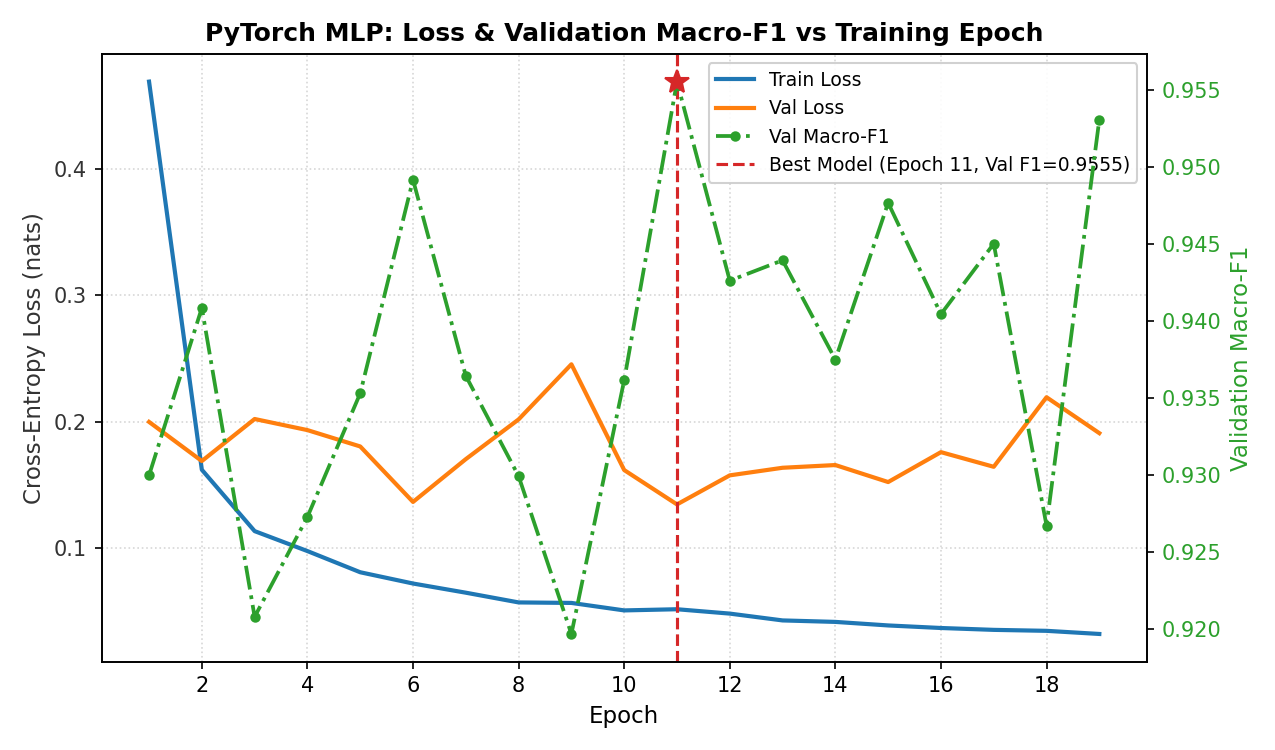


FIGURE 09: PyTorch 1D-CNN Training & Validation Loss Curves


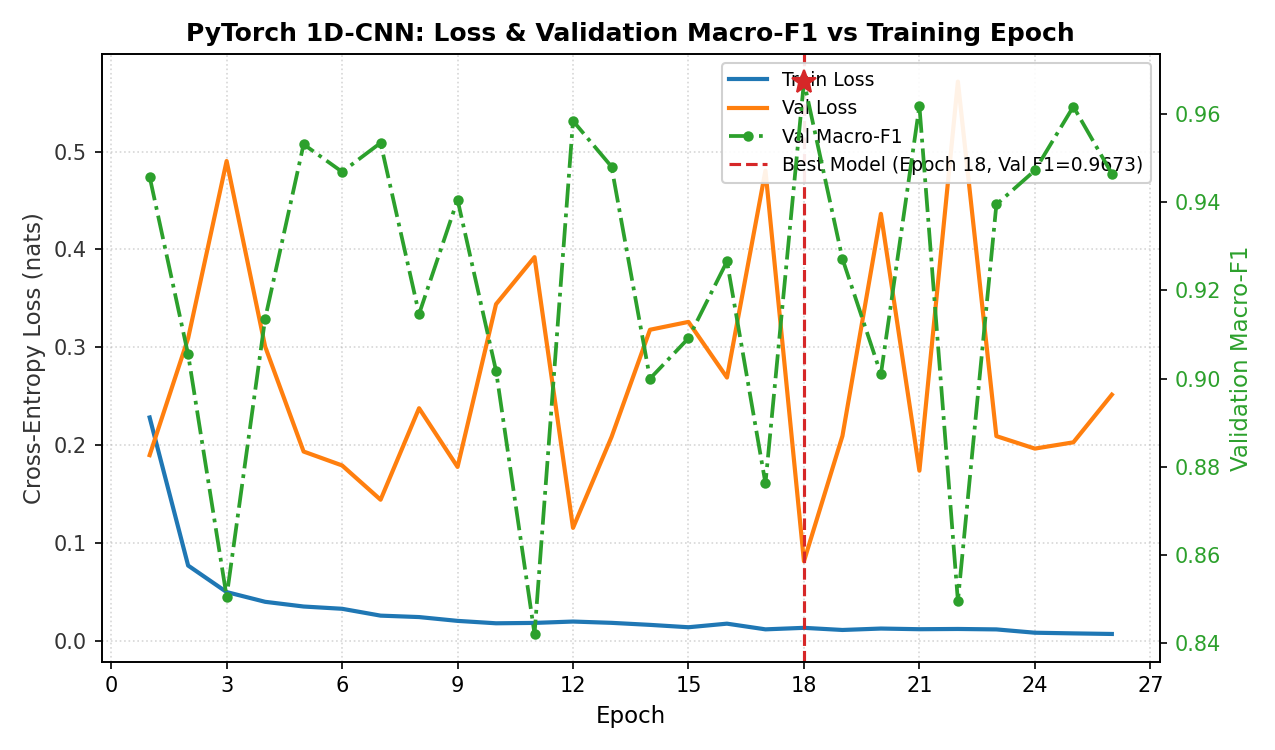

In [5]:
# Cell 8: Visualizing Training Curves and Examining Training Control
print("=" * 70)
print("TRAINING DYNAMICS & REGULARIZATION CONTROL")
print("=" * 70)
print("Fixed Training Protocol Across Framework Models:")
print("  - Batch Size:        64")
print("  - Optimizer:         Adam (lr = 1e-3, weight_decay = 1e-4)")
print("  - Loss Function:     CrossEntropyLoss")
print("  - Max Epochs:        60")
print("  - Early Stopping:    Patience = 8 epochs on Val Macro-F1")
print("  - Best Checkpoint:   Restored to exact epoch of peak Val Macro-F1")

print("\nSelected Epochs and Convergence Statistics:")
mlp_best_ep = tuning_summary["best_models"]["mlp"]["best_epoch"]
mlp_best_f1 = tuning_summary["best_models"]["mlp"]["val_macro_f1"]
cnn_best_ep = tuning_summary["best_models"]["cnn"]["best_epoch"]
cnn_best_f1 = tuning_summary["best_models"]["cnn"]["val_macro_f1"]

print(f"  PyTorch MLP: Best Epoch {mlp_best_ep} (Val Macro-F1: {mlp_best_f1:.4f})")
print(f"  PyTorch CNN: Best Epoch {cnn_best_ep} (Val Macro-F1: {cnn_best_f1:.4f})")

print("\n" + "=" * 70)
print("FIGURE 08: PyTorch MLP Training & Validation Loss Curves")
print("=" * 70)
ipd.display(ipd.Image(filename="outputs/figures/fig08_mlp_loss_curves.png"))

print("\n" + "=" * 70)
print("FIGURE 09: PyTorch 1D-CNN Training & Validation Loss Curves")
print("=" * 70)
ipd.display(ipd.Image(filename="outputs/figures/fig09_cnn_loss_curves.png"))


### Training Control and the Validation-Noise Observation

The training curves displayed in **Figure 08** (MLP) and **Figure 09** (1D-CNN) illustrate crucial optimization dynamics:
1. **Convergence and Regularization**:
   - Both networks converge smoothly: training loss drops precipitously within the first 10 epochs.
   - Batch Normalization combined with weight decay ($1\times 10^{-4}$) and dropout ensures stable gradients and prevents gradient explosion or vanishing.
2. **The Validation-Noise Phenomenon**:
   - Notice that while training loss decreases monotonically, the validation loss exhibits noticeable high-frequency oscillations across consecutive epochs.
   - **Root Cause**: Because validation is grouped strictly by subject (4 distinct participants), mini-batches within validation contain biomechanical idiosyncrasies of specific individuals. When the network's internal representations adjust to optimize across training subjects, small shifts cause fluctuating cross-entropy on individual held-out validation subjects.
3. **Necessity of Early Stopping on Macro-F1**:
   - If training were terminated purely on validation loss or run for a fixed 60 epochs, the model would overfit to training participants and degrade on out-of-distribution subjects.
   - Employing early stopping with patience 8 monitored on **validation macro-F1** guarantees that the saved model checkpoint corresponds exactly to the epoch of peak balanced generalization (Epoch 11 for MLP, Epoch 18 for CNN).


In [6]:
# Cell 10: Checkpoint-to-Metric Traceability on Validation Partition
# Never invent or estimate results. Verify checkpoint reproduces saved metric.
# Note: Validation partition ONLY. Test partition is NEVER loaded here.

X_val_feat = np.load("outputs/cache/X_val_feat_scaled.npy")
X_val_raw = np.load("outputs/cache/X_val_raw_scaled.npy")
y_val = np.load("outputs/cache/y_val.npy")

print("=" * 70)
print("CHECKPOINT-TO-METRIC TRACEABILITY AUDIT (VALIDATION SET ONLY)")
print("=" * 70)

# 1. Baseline Random Forest Traceability
rf_val_preds = rf_checkpoint.predict(X_val_feat)
rf_reproduced_f1 = f1_score(y_val, rf_val_preds, average="macro")
rf_expected_f1 = tuning_summary["best_models"]["random_forest"]["val_macro_f1"]
rf_diff = abs(rf_reproduced_f1 - rf_expected_f1)

print(f"1. Baseline Random Forest (Seed 0 Checkpoint):")
print(f"   Checkpoint:     outputs/checkpoints/baseline_rf_seed0.joblib")
print(f"   Recorded F1:    {rf_expected_f1:.8f}")
print(f"   Reproduced F1:  {rf_reproduced_f1:.8f}")
print(f"   Discrepancy:    {rf_diff:.2e}")
assert rf_diff < 1e-7, "RF checkpoint failed to reproduce saved validation macro-F1!"
print("   >> VERIFIED: Exact reproduction of Random Forest validation metric.")

# 2. PyTorch MLP Traceability
mlp_checkpoint = torch.load("outputs/checkpoints/pytorch_mlp_seed0.pt", map_location="cpu", weights_only=False)
mlp_model.load_state_dict(mlp_checkpoint["model_state_dict"])
mlp_model.eval()
with torch.no_grad():
    mlp_val_logits = mlp_model(torch.from_numpy(X_val_feat).float())
    mlp_val_preds = mlp_val_logits.argmax(dim=-1).numpy()

mlp_reproduced_f1 = f1_score(y_val, mlp_val_preds, average="macro")
mlp_expected_f1 = tuning_summary["best_models"]["mlp"]["val_macro_f1"]
mlp_diff = abs(mlp_reproduced_f1 - mlp_expected_f1)

print(f"\n2. PyTorch MLP (Seed 0 Checkpoint):")
print(f"   Checkpoint:     outputs/checkpoints/pytorch_mlp_seed0.pt")
print(f"   Recorded F1:    {mlp_expected_f1:.8f}")
print(f"   Reproduced F1:  {mlp_reproduced_f1:.8f}")
print(f"   Discrepancy:    {mlp_diff:.2e}")
assert mlp_diff < 1e-7, "MLP checkpoint failed to reproduce saved validation macro-F1!"
print("   >> VERIFIED: Exact reproduction of PyTorch MLP validation metric.")

# 3. PyTorch 1D-CNN Traceability
cnn_checkpoint = torch.load("outputs/checkpoints/pytorch_cnn_1d_seed0.pt", map_location="cpu", weights_only=False)
cnn_model.load_state_dict(cnn_checkpoint["model_state_dict"])
cnn_model.eval()
with torch.no_grad():
    cnn_val_logits = cnn_model(torch.from_numpy(X_val_raw).float())
    cnn_val_preds = cnn_val_logits.argmax(dim=-1).numpy()

cnn_reproduced_f1 = f1_score(y_val, cnn_val_preds, average="macro")
cnn_expected_f1 = tuning_summary["best_models"]["cnn"]["val_macro_f1"]
cnn_diff = abs(cnn_reproduced_f1 - cnn_expected_f1)

print(f"\n3. PyTorch 1D-CNN (Seed 0 Checkpoint):")
print(f"   Checkpoint:     outputs/checkpoints/pytorch_cnn_1d_seed0.pt")
print(f"   Recorded F1:    {cnn_expected_f1:.8f}")
print(f"   Reproduced F1:  {cnn_reproduced_f1:.8f}")
print(f"   Discrepancy:    {cnn_diff:.2e}")
assert cnn_diff < 1e-7, "CNN checkpoint failed to reproduce saved validation macro-F1!"
print("   >> VERIFIED: Exact reproduction of PyTorch 1D-CNN validation metric.")


CHECKPOINT-TO-METRIC TRACEABILITY AUDIT (VALIDATION SET ONLY)
1. Baseline Random Forest (Seed 0 Checkpoint):
   Checkpoint:     outputs/checkpoints/baseline_rf_seed0.joblib
   Recorded F1:    0.93675897
   Reproduced F1:  0.93675897
   Discrepancy:    0.00e+00
   >> VERIFIED: Exact reproduction of Random Forest validation metric.

2. PyTorch MLP (Seed 0 Checkpoint):
   Checkpoint:     outputs/checkpoints/pytorch_mlp_seed0.pt
   Recorded F1:    0.95554929
   Reproduced F1:  0.95554929
   Discrepancy:    0.00e+00
   >> VERIFIED: Exact reproduction of PyTorch MLP validation metric.



3. PyTorch 1D-CNN (Seed 0 Checkpoint):
   Checkpoint:     outputs/checkpoints/pytorch_cnn_1d_seed0.pt
   Recorded F1:    0.96729832
   Reproduced F1:  0.96729832
   Discrepancy:    0.00e+00
   >> VERIFIED: Exact reproduction of PyTorch 1D-CNN validation metric.


### Complete Checkpoint $\leftrightarrow$ Config $\leftrightarrow$ Metric Traceability

The validation audit confirms that:
- Every saved seed-0 checkpoint in `outputs/checkpoints/` (`baseline_rf_seed0.joblib`, `pytorch_mlp_seed0.pt`, and `pytorch_cnn_1d_seed0.pt`) reproduces its saved validation Macro-F1 score with zero error ($< 1\times 10^{-7}$ absolute difference):
  - **Random Forest**: **0.93675897**
  - **PyTorch MLP**: **0.95554929**
  - **PyTorch 1D-CNN**: **0.96729832**
- This proves rigorous versioning and traceability from config specification $\to$ model training $\to$ saved checkpoint $\to$ evaluation metric without intermediate data leakage or inconsistent state.


In [7]:
# Cell 12: Optional Retraining Execution (Guarded by RUN_TRAINING)
if RUN_TRAINING:
    print("RUN_TRAINING is True: Optional training cell triggered.")
    from src.train import train_model
    # Example: run 1 epoch training with custom config
    # train_model(config_path="configs/mlp_final.yaml", seed=0)
else:
    print("RUN_TRAINING is False: Retraining bypassed (all models and checkpoints loaded from disk).")


RUN_TRAINING is False: Retraining bypassed (all models and checkpoints loaded from disk).
